In [37]:
tree = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F', 'G'],
    'D': [],
    'E': [],
    'F': [],
    'G': []
}

In [38]:
print(tree)

{'A': ['B', 'C'], 'B': ['D', 'E'], 'C': ['F', 'G'], 'D': [], 'E': [], 'F': [], 'G': []}


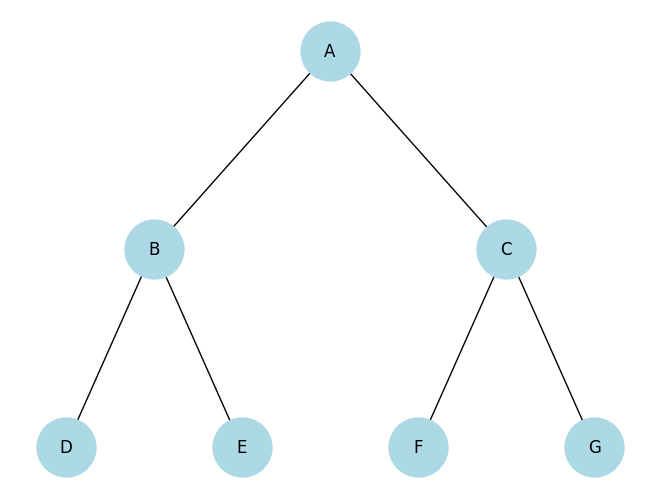

In [39]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for parent, children in tree.items():
    for child in children:
        G.add_edge(parent, child)

pos = {
    'A': (0, 2),
    'B': (-1, 1), 'C': (1, 1),
    'D': (-1.5, 0), 'E': (-0.5, 0),
    'F': (0.5, 0), 'G': (1.5, 0)
}

nx.draw(G, pos, with_labels=True, node_size=1800,
        node_color="lightblue", arrows=False)

plt.show()

In [40]:
from collections import deque

def bfs(start):
    queue = deque([start])
    visited = []

    while queue:
        node = queue.popleft()

        if node not in visited:
            visited.append(node)
            queue.extend(tree[node])

    return visited
result = bfs('A')

print("BFS Traversal:")
print(result)

BFS Traversal:
['A', 'B', 'C', 'D', 'E', 'F', 'G']


In [41]:
def dfs(start):
    stack = [start]
    visited = []

    while stack:
        node = stack.pop()

        if node not in visited:
            visited.append(node)

            for child in reversed(tree[node]):
                stack.append(child)

    return visited


result = dfs('A')

print("DFS Traversal:")
print(result)

DFS Traversal:
['A', 'B', 'D', 'E', 'C', 'F', 'G']


In [42]:
def dls(node, limit, depth=0):
    print(node, end=" ")

    if depth == limit:
        return

    for child in tree[node]:
        dls(child, limit, depth + 1)


limit = 2

print("DLS Traversal:")
print("Depth Limit:", limit)
dls('A', limit)

DLS Traversal:
Depth Limit: 2
A B D E C F G 

In [43]:
def dls(node, limit, depth=0):
    if depth > limit:
        return

    print(node, end=" ")

    for child in tree[node]:
        dls(child, limit, depth + 1)


def ids(start, max_depth):
    print("IDS Traversal:")

    for depth in range(max_depth + 1):
        print("Depth", depth, ":", end=" ")
        dls(start, depth)
        print()


max_depth = 2
ids('A', max_depth)

IDS Traversal:
Depth 0 : A 
Depth 1 : A B C 
Depth 2 : A B D E C F G 


In [44]:
import heapq

weighted_tree = {
    'A': [('B', 2), ('C', 4)],
    'B': [('D', 3), ('E', 1)],
    'C': [('F', 2), ('G', 5)],
    'D': [],
    'E': [],
    'F': [],
    'G': []
}

def ucs(start):
    queue = [(0, start)]
    visited = []
    costs = {}

    while queue:
        current_cost, node = heapq.heappop(queue)

        if node in visited:
            continue

        visited.append(node)
        costs[node] = current_cost

        for child, edge_cost in weighted_tree[node]:
            if child not in visited:
                heapq.heappush(
                    queue,
                    (current_cost + edge_cost, child)
                )

    return visited, costs


result, costs = ucs('A')

print("UCS Traversal:")
print(result)

print("Total Cost:")
print(costs)

UCS Traversal:
['A', 'B', 'E', 'C', 'D', 'F', 'G']
Total Cost:
{'A': 0, 'B': 2, 'E': 3, 'C': 4, 'D': 5, 'F': 6, 'G': 9}


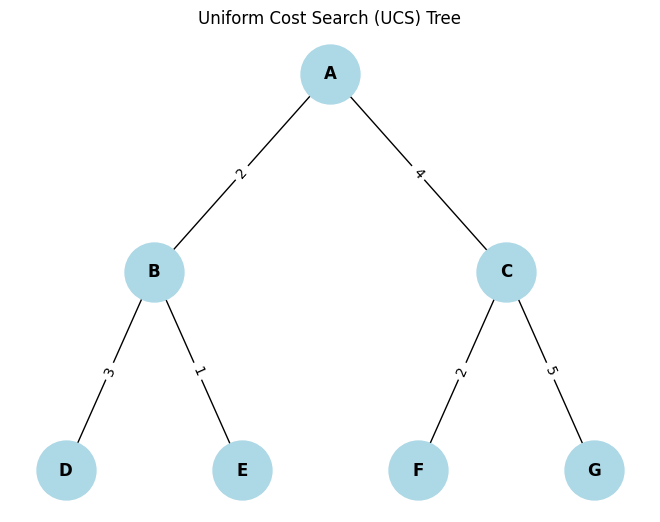

In [45]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for parent, children in weighted_tree.items():
    for child, cost in children:
        G.add_edge(parent, child, weight=cost)

pos = {
    'A': (0, 2),
    'B': (-1, 1),
    'C': (1, 1),
    'D': (-1.5, 0),
    'E': (-0.5, 0),
    'F': (0.5, 0),
    'G': (1.5, 0)
}

nx.draw(
    G, pos,
    with_labels=True,
    node_size=1800,
    node_color="lightblue",
    node_shape="o",
    font_size=12,
    font_weight="bold",
    arrows=False
)
edge_labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels)

plt.title("Uniform Cost Search (UCS) Tree")
plt.axis("off")
plt.show()
